# V12 — Filling

**Objetivo:** prever quais clientes vão cancelar o serviço (churn) com regressão logística.

## Extração dos dados

### Bibliotecas

In [2]:
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

### Configuração

Todos os valores que podem mudar entre versões ficam aqui. Para testar uma variação, altere esta célula e rode o notebook inteiro (*Restart Kernel → Run All*).

In [3]:
# --- Caminhos (relativos à pasta deste notebook) ---
CAMINHO_DATASET = Path("../../../data/raw/Telco-Customer-Churn.csv")
PASTA_METRICAS = Path("metrics")

# --- Reprodutibilidade e divisão dos dados ---
RANDOM_STATE = 42
PROPORCAO_TESTE = 0.3
N_FOLDS = 5

# --- Tradução das colunas para português ---
COLUNAS_PT_BR = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_acumulado",
    "Churn": "target",
}

# --- Identificador e atributos sensíveis (não entram no modelo) ---
COLUNAS_SENSIVEIS = ["id_cliente", "genero", "dependentes"]

# --- Codificação das categóricas ---
MAPA_SIM_NAO = {"Yes": 1, "No": 0}
COLUNAS_SIM_NAO = ["casado", "fatura_sem_papel", "possui_servico_telefonico"]

COLUNAS_ADDONS = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
MAPA_ADDON = {"Yes": 1, "No": 0, "No internet service": 0}
MAPA_MULTIPLAS_LINHAS = {"Yes": 1, "No": 0, "No phone service": 0}
MAPA_TIPO_CONTRATO = {"Month-to-month": 0, "One year": 1, "Two year": 2}

COLUNAS_ONE_HOT = {
    "possui_servico_de_internet": {"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"},
    "metodo_pagamento": {
        "Mailed check": "mailed_check",
        "Electronic check": "electronic_check",
        "Bank transfer (automatic)": "bank_transfer_automatic",
        "Credit card (automatic)": "credit_card_automatic",
    },
}

# --- Features ---
COLUNA_REDUNDANTE = "total_cobrado_acumulado"
COLUNAS_NUMERICAS_EDA = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]
FAIXAS_DE_MESES = [0, 6, 12, 24, 48, 72]
COLUNAS_PARA_ESCALONAR = ["taxa_churn_faixa_meses", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

# --- Modelo: regressão logística com penalidade L1 (Lasso) ---
PARAMETROS_MODELO = {"l1_ratio": 1.0, "solver": "liblinear", "C": 1.0, "max_iter": 2000, "random_state": RANDOM_STATE}

### Carregamento

In [4]:
df_bruto = pd.read_csv(CAMINHO_DATASET)

df_bruto.head(n=100)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Tradução das colunas para português

In [5]:
df_traduzido = df_bruto.rename(columns=COLUNAS_PT_BR)

df_traduzido.head(n=100)

,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_acumulado,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Target binário

`Churn` vira `target`: **1 = cancelou**, **0 = não cancelou**.

In [6]:
df_traduzido["target"] = df_traduzido["target"].map(MAPA_SIM_NAO)

df_traduzido["target"].value_counts()

target
0    5174
1    1869
Name: count, dtype: int64

## Remoção de features sensíveis

- `id_cliente`: identificador único, não tem relação com o comportamento do cliente.
- `genero` e `dependentes`: atributos sensíveis, removidos para evitar decisões discriminatórias.

In [7]:
df_sem_sensiveis = df_traduzido.drop(columns=COLUNAS_SENSIVEIS)

df_sem_sensiveis.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_acumulado,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Codificação das features categóricas

O modelo só trabalha com números, então cada tipo de coluna categórica recebe um tratamento:

| Tipo | Colunas | Codificação |
|---|---|---|
| Sim/Não | `casado`, `fatura_sem_papel`, `possui_servico_telefonico` | `Yes` → 1, `No` → 0 |
| Addons de internet | segurança, backup, proteção, suporte, streaming de TV e de filmes | `Yes` → 1; `No` e `No internet service` → 0 |
| Múltiplas linhas | `possui_multiplas_linhas` | `Yes` → 1; `No` e `No phone service` → 0 |
| Ordinal | `tipo_contrato` | mensal → 0, 1 ano → 1, 2 anos → 2 (existe uma ordem natural) |
| Sem ordem | `possui_servico_de_internet`, `metodo_pagamento` | One-hot: uma coluna 0/1 para cada categoria |

In [8]:
def codificar_categoricas(df):
    """Converte todas as colunas categóricas em números, conforme os mapas da configuração."""
    df = df.copy()

    for coluna in COLUNAS_SIM_NAO:
        df[coluna] = df[coluna].map(MAPA_SIM_NAO)
    for coluna in COLUNAS_ADDONS:
        df[coluna] = df[coluna].map(MAPA_ADDON)
    df["possui_multiplas_linhas"] = df["possui_multiplas_linhas"].map(MAPA_MULTIPLAS_LINHAS)
    df["tipo_contrato"] = df["tipo_contrato"].map(MAPA_TIPO_CONTRATO)

    for coluna, mapa in COLUNAS_ONE_HOT.items():
        dummies = pd.get_dummies(df[coluna].map(mapa), prefix=coluna, dtype=int)
        df = pd.concat([df.drop(columns=coluna), dummies], axis=1)

    return df


df_codificado = codificar_categoricas(df_sem_sensiveis)

df_codificado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.5,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.7,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.2,0,0,0,1,1,0,0,0


## Informações estruturais

Depois da codificação, todas as colunas devem ser numéricas. A única exceção esperada é `total_cobrado_acumulado`, que vem do CSV como texto e é tratada na próxima etapa.

In [9]:
df_codificado.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   cliente_em_idade_avancada                 7043 non-null   int64  
 1   casado                                    7043 non-null   int64  
 2   meses_como_cliente                        7043 non-null   int64  
 3   possui_servico_telefonico                 7043 non-null   int64  
 4   possui_multiplas_linhas                   7043 non-null   int64  
 5   possui_seguranca_online                   7043 non-null   int64  
 6   possui_backup_online                      7043 non-null   int64  
 7   possui_protecao_dispositivo               7043 non-null   int64  
 8   possui_suporte_tecnico_premium            7043 non-null   int64  
 9   possui_streaming_tv_terceiros             7043 non-null   int64  
 10  possui_streaming_filmes_terceiros         7043 

## Identificando missing values

O `isna()` não encontra nenhum nulo, mas isso engana: `total_cobrado_acumulado` tem **11 valores em branco (`" "`)**, que o pandas lê como texto.

Convertendo a coluna para número (`errors="coerce"` transforma o que não é número em `NaN`), esses valores aparecem. Todos pertencem a clientes com **0 meses de casa**, que ainda não receberam a primeira fatura.

In [10]:
print(f"Nulos encontrados pelo isna(): {df_codificado.isna().sum().sum()}")

total_cobrado_numerico = pd.to_numeric(df_codificado["total_cobrado_acumulado"], errors="coerce")
clientes_sem_fatura = (df_codificado["meses_como_cliente"] == 0) & total_cobrado_numerico.isna()
print(f"Valores em branco no total cobrado: {total_cobrado_numerico.isna().sum()}")

df_codificado[clientes_sem_fatura]

Nulos encontrados pelo isna(): 0
Valores em branco no total cobrado: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,,0,1,0,0,0,0,0,1


## Fazendo filling dos missing values

Os 11 clientes sem fatura recebem valores igual a 0 (0,16% da base). Não faria sentido aplicar média ou médiana por serem clientes que não tem meses ainda

In [11]:
df_limpo = df_codificado.copy()
df_limpo["total_cobrado_acumulado"] = total_cobrado_numerico.fillna(0)

print(f"Valores preenchidos: {clientes_sem_fatura.sum()}")
print(f"Nulos restantes no total cobrado: {df_limpo['total_cobrado_acumulado'].isna().sum()}")
print(f"Registros mantidos: {len(df_limpo)}")

df_limpo[clientes_sem_fatura]

Valores preenchidos: 11
Nulos restantes no total cobrado: 0
Registros mantidos: 7043


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,0.0,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,0.0,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,0.0,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,0.0,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,0.0,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,0.0,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,0.0,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,0.0,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,0.0,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,0.0,0,1,0,0,0,0,0,1


## Engenharia de features: quantidade de addons contratados

Soma quantos serviços adicionais de internet o cliente tem (de 0 a 6).

In [12]:
df_limpo["quantidade_de_addons"] = df_limpo[COLUNAS_ADDONS].sum(axis=1)

df_limpo.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_acumulado,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0,0


## Análise de distribuição e mapa de calor de correlação

Objetivos:
- ver o formato da distribuição das variáveis numéricas;
- encontrar pares de features muito correlacionados entre si (|correlação| ≥ 0,5), que trazem informação repetida;
- ver quais features têm mais relação com o target.

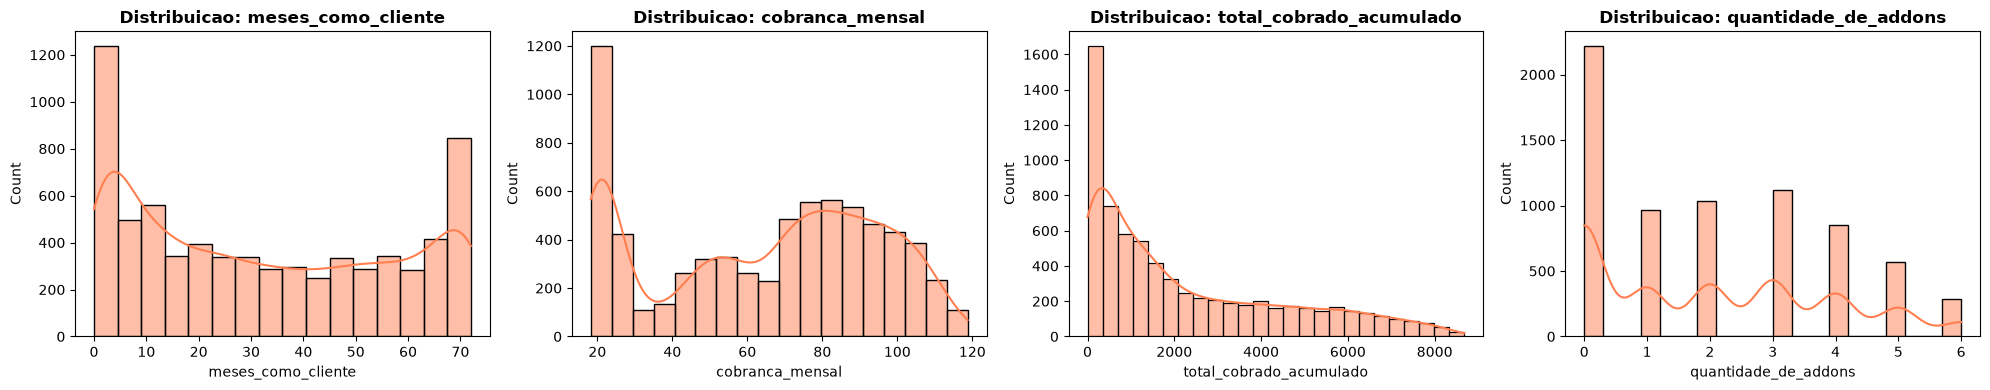

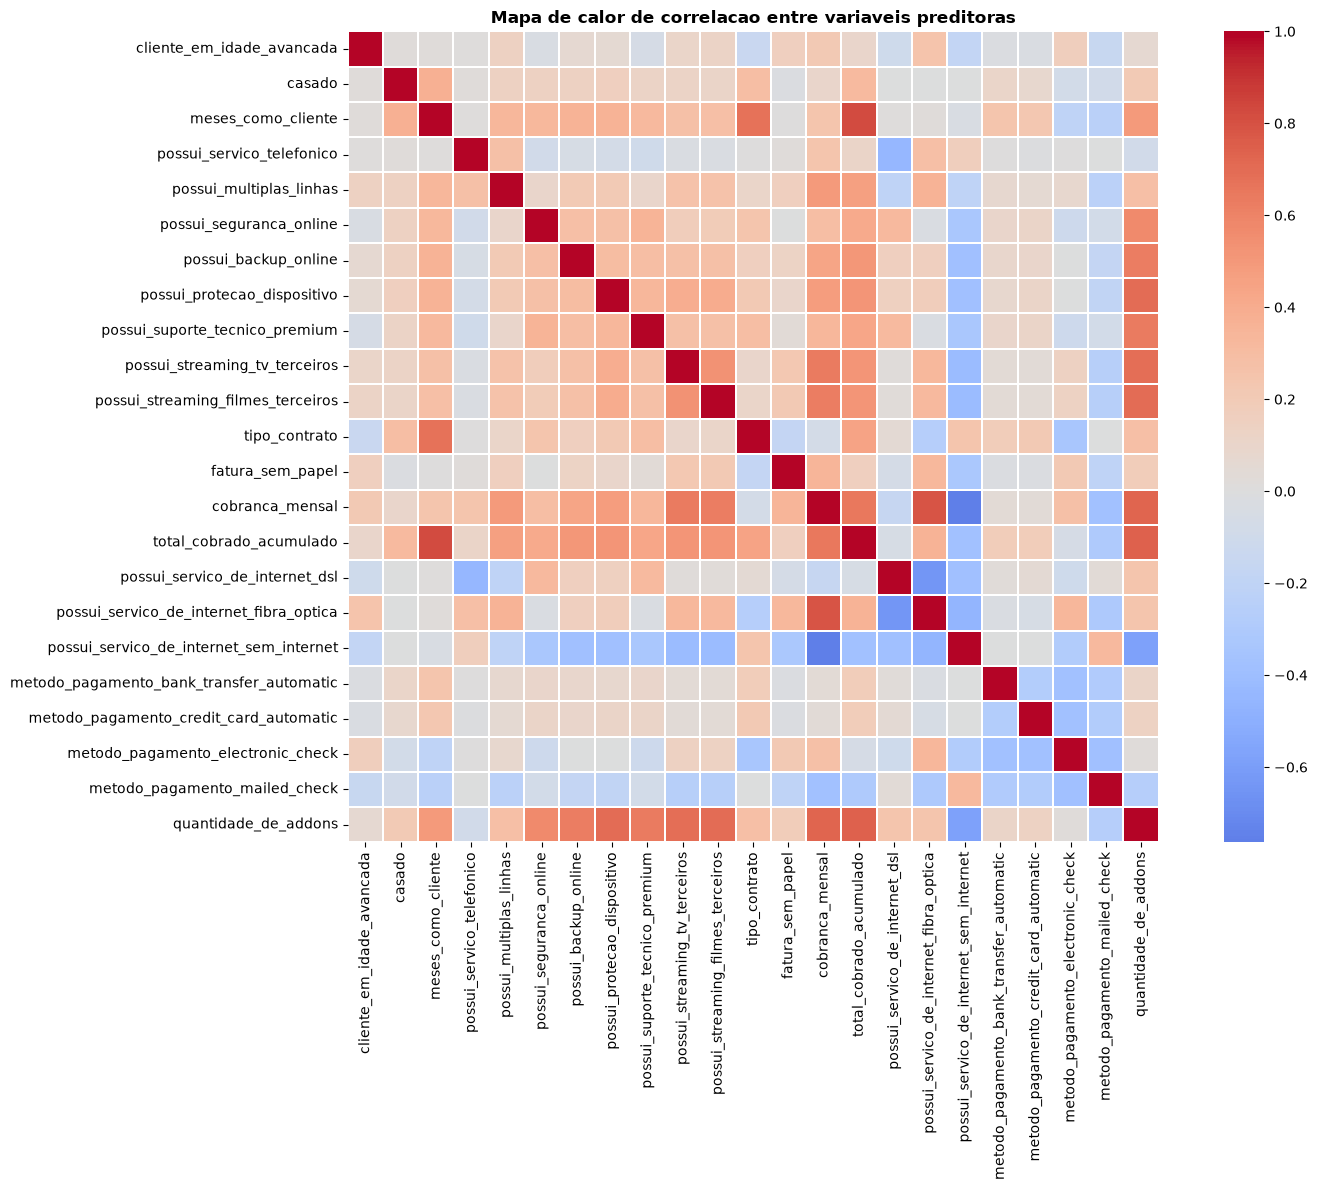

Pares de features preditoras com |correlacao| >= 0.5:
meses_como_cliente                       total_cobrado_acumulado                    0.826
cobranca_mensal                          possui_servico_de_internet_fibra_optica    0.787
                                         possui_servico_de_internet_sem_internet   -0.764
total_cobrado_acumulado                  quantidade_de_addons                       0.745
cobranca_mensal                          quantidade_de_addons                       0.725
possui_protecao_dispositivo              quantidade_de_addons                       0.693
possui_streaming_filmes_terceiros        quantidade_de_addons                       0.693
possui_streaming_tv_terceiros            quantidade_de_addons                       0.688
meses_como_cliente                       tipo_contrato                              0.672
cobranca_mensal                          total_cobrado_acumulado                    0.651
possui_servico_de_internet_dsl           possu

In [13]:
colunas_distribuicao = ["meses_como_cliente", "cobranca_mensal", "total_cobrado_acumulado", "quantidade_de_addons"]

fig, axes = plt.subplots(1, len(colunas_distribuicao), figsize=(20, 4))
for ax, coluna in zip(axes, colunas_distribuicao):
    sns.histplot(df_limpo[coluna], kde=True, ax=ax, color="coral")
    ax.set_title(f"Distribuicao: {coluna}", fontweight="bold")
plt.tight_layout()
plt.show()

matriz_correlacao = df_limpo.drop(columns="target").corr()

plt.figure(figsize=(16, 12))
sns.heatmap(matriz_correlacao, cmap="coolwarm", center=0, square=True, linewidths=0.3)
plt.title("Mapa de calor de correlacao entre variaveis preditoras", fontweight="bold")
plt.tight_layout()
plt.show()

# Mantém só o triângulo superior da matriz para não repetir os pares
pares = matriz_correlacao.where(np.triu(np.ones(matriz_correlacao.shape, dtype=bool), k=1)).stack()
pares_alta_correlacao = pares[pares.abs() >= 0.5].sort_values(key=abs, ascending=False)
print("Pares de features preditoras com |correlacao| >= 0.5:")
print(pares_alta_correlacao.round(3).to_string())

print("\nCorrelacao de cada feature com o target:")
print(df_limpo.corr()["target"].drop("target").sort_values(key=abs, ascending=False).round(3).to_string())

## Removendo feature redundante por alta colinearidade

`total_cobrado_acumulado` tem correlação de ~0,83 com `meses_como_cliente`: o total cobrado é, na prática, o tempo de casa multiplicado pela mensalidade. Manter as duas atrapalha a interpretação dos coeficientes, então o total cobrado sai.

In [14]:
df_sem_redundante = df_limpo.drop(columns=COLUNA_REDUNDANTE)

df_sem_redundante.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,0,0,0,1,1,0,0,0,0


## Removendo linhas duplicadas

Clientes com todas as features idênticas poderiam cair ao mesmo tempo no treino e no teste, o que deixaria a avaliação otimista.

In [15]:
df_modelagem = df_sem_redundante.drop_duplicates()

print(f"Linhas duplicadas encontradas: {len(df_sem_redundante) - len(df_modelagem)}")
print(f"Registros antes: {len(df_sem_redundante)}, Registros depois: {len(df_modelagem)}")

Linhas duplicadas encontradas: 73
Registros antes: 7043, Registros depois: 6970


## Proporção da variável target

O dataset é **desbalanceado**: cerca de 1 em cada 4 clientes cancela. Por isso:
- a acurácia sozinha engana (prever "ninguém cancela" já acerta ~74%);
- o treino usa **SMOTE** para equilibrar as classes.

Contagem:
target
0    5128
1    1842

Percentual:
Nao cancelou: 73.57%
Cancelou: 26.43%


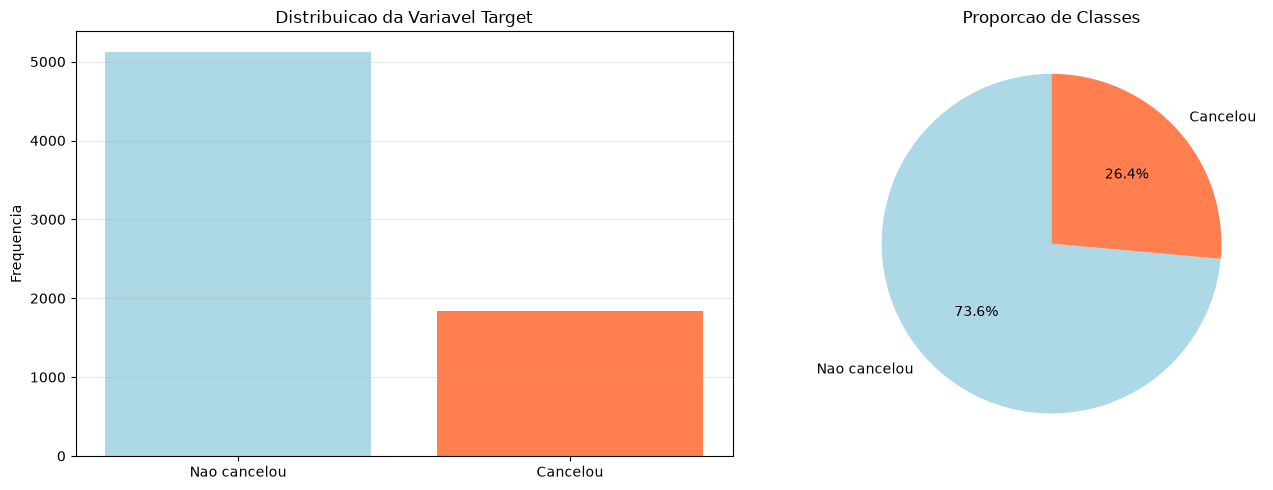


Ratio de balanceamento: 0.36


In [16]:
contagem_target = df_modelagem["target"].value_counts().sort_index()
rotulos = ["Nao cancelou", "Cancelou"]

print("Contagem:")
print(contagem_target.to_string())
print("\nPercentual:")
for rotulo, percentual in zip(rotulos, contagem_target / contagem_target.sum() * 100):
    print(f"{rotulo}: {percentual:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(rotulos, contagem_target.values, color=["lightblue", "coral"])
axes[0].set_ylabel("Frequencia")
axes[0].set_title("Distribuicao da Variavel Target")
axes[0].grid(axis="y", alpha=0.3)
axes[1].pie(contagem_target.values, labels=rotulos, autopct="%1.1f%%", colors=["lightblue", "coral"], startangle=90)
axes[1].set_title("Proporcao de Classes")
plt.tight_layout()
plt.show()

print(f"\nRatio de balanceamento: {contagem_target.min() / contagem_target.max():.2f}")

## Análise de dispersão das variáveis numéricas

Boxplots para verificar outliers. Um valor é contado como outlier quando está a mais de 3 desvios padrão da média (|z-score| > 3).

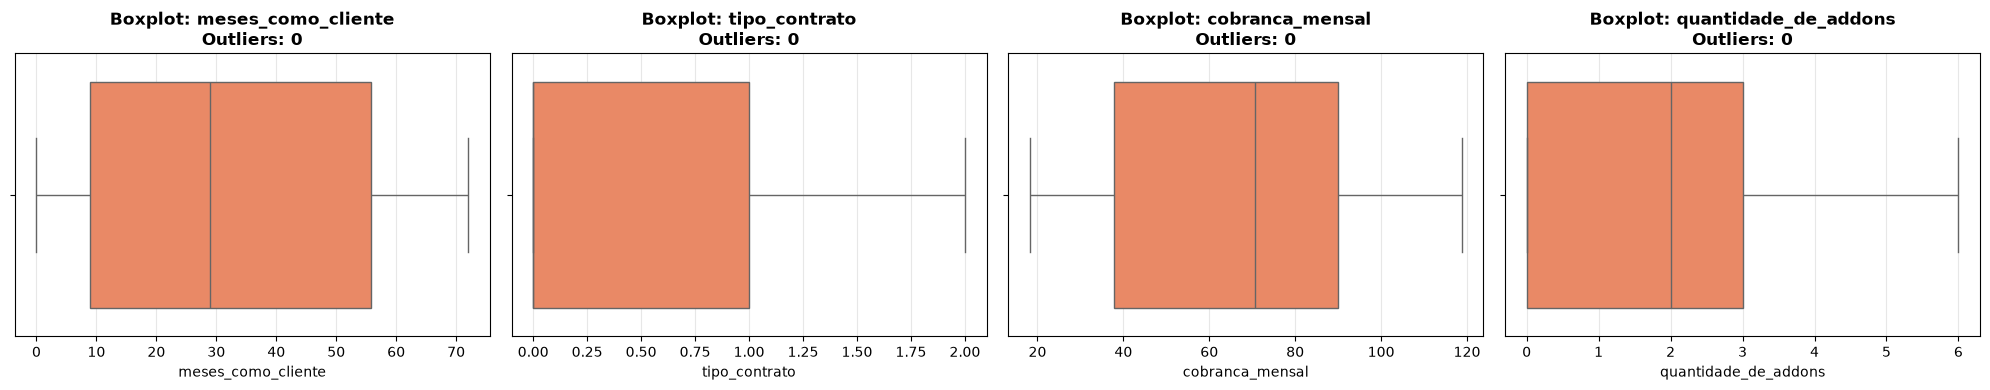

In [17]:
fig, axes = plt.subplots(1, len(COLUNAS_NUMERICAS_EDA), figsize=(20, 4))
for ax, coluna in zip(axes, COLUNAS_NUMERICAS_EDA):
    sns.boxplot(x=df_modelagem[coluna], ax=ax, color="coral")
    quantidade_outliers = (np.abs(stats.zscore(df_modelagem[coluna])) > 3).sum()
    ax.set_title(f"Boxplot: {coluna}\nOutliers: {quantidade_outliers}", fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Informações estatísticas

In [18]:
df_modelagem[COLUNAS_NUMERICAS_EDA].describe().round(2)

,meses_como_cliente,tipo_contrato,cobranca_mensal,quantidade_de_addons
count,6970.00,6970.00,6970.00,6970.00
mean,32.57,0.69,65.08,2.06
std,24.47,0.83,29.97,1.84
min,0.00,0.00,18.25,0.00
25%,9.00,0.00,37.80,0.00
50%,29.00,0.00,70.55,2.00
75%,55.75,1.00,89.95,3.00
max,72.00,2.00,118.75,6.00


## Dividindo dados entre treino e teste

70% treino e 30% teste, com `stratify` para manter a mesma proporção de churn nos dois conjuntos.

In [19]:
X = df_modelagem.drop(columns="target")
y = df_modelagem["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=PROPORCAO_TESTE, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (4879, 22), X_test: (2091, 22), y_train: (4879,), y_test: (2091,)


## Engenharia de features: taxa de churn por faixa de meses

`meses_como_cliente` é trocado pelo **% de clientes que cancelaram na faixa de meses** do cliente:

| Faixa | Clientes com |
|---|---|
| 1ª | 1 a 6 meses |
| 2ª | 7 a 12 meses |
| 3ª | 13 a 24 meses |
| 4ª | 25 a 48 meses |
| 5ª | 49 a 72 meses |

As faixas são mais estreitas no início, onde o risco muda rápido, e mais largas no fim, onde ele quase não muda.

> **Cuidado com vazamento de dados:** essa feature usa o `target`. A taxa de cada faixa é calculada **só com os dados de treino** e depois aplicada nos dados de avaliação. Se fosse calculada com a base inteira, o modelo "veria" as respostas do teste e as métricas ficariam otimistas.

In [20]:
def adicionar_taxa_de_churn_por_faixa_de_meses(X_treino, X_avaliacao, y_treino):
    """Troca meses_como_cliente pela taxa de churn da faixa, aprendida apenas com o treino."""
    X_treino, X_avaliacao = X_treino.copy(), X_avaliacao.copy()
    faixa_treino = pd.cut(X_treino["meses_como_cliente"], FAIXAS_DE_MESES, include_lowest=True)
    faixa_avaliacao = pd.cut(X_avaliacao["meses_como_cliente"], FAIXAS_DE_MESES, include_lowest=True)

    # Média do target (0/1) em cada faixa = % de clientes que cancelaram naquela faixa
    taxa_de_churn_por_faixa = y_treino.groupby(faixa_treino, observed=False).mean()

    X_treino["taxa_churn_faixa_meses"] = faixa_treino.map(taxa_de_churn_por_faixa).astype(float)
    X_avaliacao["taxa_churn_faixa_meses"] = faixa_avaliacao.map(taxa_de_churn_por_faixa).astype(float)

    return X_treino.drop(columns="meses_como_cliente"), X_avaliacao.drop(columns="meses_como_cliente")


# Taxa aprendida em cada faixa usando o conjunto de treino
faixas_treino = pd.cut(X_train["meses_como_cliente"], FAIXAS_DE_MESES, include_lowest=True)
y_train.groupby(faixas_treino, observed=False).agg(clientes="size", taxa_de_churn="mean").round(3)

,clientes,taxa_de_churn
meses_como_cliente,,
"(-0.001, 6.0]",998,0.516
"(6.0, 12.0]",491,0.369
"(12.0, 24.0]",727,0.290
"(24.0, 48.0]",1131,0.202
"(48.0, 72.0]",1532,0.101


## Preparação para o treino: taxa por faixa, escalonamento e SMOTE

As três etapas ficam em uma única função, usada tanto no treino final quanto em cada fold da validação cruzada. Todas aprendem **apenas com o treino**:

1. **Taxa de churn por faixa de meses** (seção anterior).
2. **Escalonamento** (`StandardScaler`): deixa as colunas numéricas com média 0 e desvio 1, para que nenhuma domine o modelo só por ter valores maiores.
3. **SMOTE**: cria exemplos sintéticos da classe minoritária (churn) até as classes ficarem do mesmo tamanho. É aplicado **só no treino**; os dados de avaliação continuam com a proporção real.

In [21]:
def preparar_para_treino(X_treino, X_avaliacao, y_treino):
    """Aplica taxa por faixa, escalonamento e SMOTE. Retorna treino balanceado e avaliação transformada."""
    X_treino, X_avaliacao = adicionar_taxa_de_churn_por_faixa_de_meses(X_treino, X_avaliacao, y_treino)

    escalonador = StandardScaler()
    X_treino[COLUNAS_PARA_ESCALONAR] = escalonador.fit_transform(X_treino[COLUNAS_PARA_ESCALONAR])
    X_avaliacao[COLUNAS_PARA_ESCALONAR] = escalonador.transform(X_avaliacao[COLUNAS_PARA_ESCALONAR])

    X_treino_balanceado, y_treino_balanceado = SMOTE(random_state=RANDOM_STATE).fit_resample(X_treino, y_treino)
    return X_treino_balanceado, y_treino_balanceado, X_avaliacao


X_train_balanceado, y_train_balanceado, X_test_preparado = preparar_para_treino(X_train, X_test, y_train)

print("Distribuicao antes do SMOTE:")
print(y_train.value_counts().to_string())
print("\nDistribuicao depois do SMOTE:")
print(y_train_balanceado.value_counts().to_string())

X_train_balanceado.head(n=100)

Distribuicao antes do SMOTE:
target
0    3590
1    1289

Distribuicao depois do SMOTE:
target
0    3590
1    3590


,cliente_em_idade_avancada,casado,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons,taxa_churn_faixa_meses
0,0,0,0,0,1,0,0,0,0,0,-0.830177,0,-1.182831,1,0,0,1,0,0,0,-0.571460,1.643099
1,1,1,0,0,1,1,1,0,0,0,1.575782,1,-0.765075,1,0,0,0,0,1,0,0.513214,-1.067859
2,0,0,1,0,0,1,1,0,1,1,1.575782,1,1.163285,0,1,0,0,0,1,0,1.055551,-1.067859
3,0,0,0,0,0,1,0,0,0,0,0.372803,0,-1.161108,1,0,0,0,0,0,1,-0.571460,-1.067859
4,0,1,1,0,0,0,0,0,1,1,0.372803,1,-0.003089,1,0,0,0,0,1,0,-0.029123,0.169898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,1,1,1,1,0,1,1,1,1.575782,1,0.723806,1,0,0,1,0,0,0,1.597888,-1.067859
96,0,1,1,1,1,1,1,1,1,0,1.575782,0,0.479837,1,0,0,0,1,0,0,1.597888,-1.067859
97,0,0,1,0,1,0,0,0,0,0,-0.830177,1,0.339471,0,1,0,1,0,0,0,-0.571460,0.169898
98,0,0,1,0,0,0,0,0,0,0,-0.830177,1,-1.480273,0,0,1,0,0,0,1,-1.113797,1.643099


## Modelo e métricas

Funções compartilhadas pela validação cruzada e pelo treino final.

| Métrica | O que responde |
|---|---|
| **Acurácia** | Quantos clientes o modelo classificou certo, no total |
| **Precisão** | Dos clientes apontados como churn, quantos realmente cancelaram |
| **Recall** | Dos clientes que cancelaram, quantos o modelo encontrou |
| **F1-score** | Equilíbrio entre precisão e recall |
| **ROC AUC** | O quanto o modelo dá nota maior para quem cancela do que para quem fica, independente do limiar |

In [22]:
def treinar_modelo(X_treino, y_treino):
    """Treina a regressão logística com penalidade L1 (Lasso)."""
    return LogisticRegression(**PARAMETROS_MODELO).fit(X_treino, y_treino)


def avaliar_modelo(modelo, X_avaliacao, y_avaliacao):
    """Calcula as métricas de classificação do modelo (limiar padrão de 0,5)."""
    y_previsto = modelo.predict(X_avaliacao)
    y_proba = modelo.predict_proba(X_avaliacao)[:, 1]
    return {
        "acuracia": accuracy_score(y_avaliacao, y_previsto),
        "precisao": precision_score(y_avaliacao, y_previsto),
        "recall": recall_score(y_avaliacao, y_previsto),
        "f1_score": f1_score(y_avaliacao, y_previsto),
        "roc_auc": roc_auc_score(y_avaliacao, y_proba),
    }

## Validação cruzada estratificada (K-Fold)

Os dados são divididos em 5 partes (folds). Cada fold serve uma vez como validação, enquanto os outros 4 treinam o modelo. Isso mostra se o desempenho é estável ou se depende da divisão dos dados.

- **Estratificada:** cada fold mantém a proporção de churn da base.
- Em cada fold, `preparar_para_treino` recalcula a taxa por faixa, o escalonamento e o SMOTE **só com o treino daquele fold**.
- Com `random_state` fixo, os folds são os mesmos do V10. Dá para comparar as duas versões fold a fold.

**Como ler:** o `+/-` é o desvio padrão entre os folds. Diferenças entre versões menores que esse valor podem ser só variação natural.

In [23]:
k_fold_estratificado = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

metricas_por_fold = []
for numero_fold, (indice_treino, indice_validacao) in enumerate(k_fold_estratificado.split(X, y), start=1):
    X_treino_fold, y_treino_fold, X_validacao_fold = preparar_para_treino(
        X.iloc[indice_treino], X.iloc[indice_validacao], y.iloc[indice_treino]
    )
    modelo_fold = treinar_modelo(X_treino_fold, y_treino_fold)
    metricas_por_fold.append({"fold": numero_fold, **avaliar_modelo(modelo_fold, X_validacao_fold, y.iloc[indice_validacao])})

tabela_metricas_cv = pd.DataFrame(metricas_por_fold)
print("Metricas por fold:")
print(tabela_metricas_cv.round(4).to_string(index=False))

print("\nMedia +/- desvio padrao entre os 5 folds:")
for coluna in tabela_metricas_cv.columns.drop("fold"):
    print(f"{coluna}: {tabela_metricas_cv[coluna].mean():.4f} +/- {tabela_metricas_cv[coluna].std():.4f}")

Metricas por fold:
 fold  acuracia  precisao  recall  f1_score  roc_auc
    1    0.8092    0.6138  0.7473    0.6740   0.8602
    2    0.7791    0.5673  0.6875    0.6216   0.8356
    3    0.7791    0.5647  0.7120    0.6298   0.8502
    4    0.7461    0.5152  0.6911    0.5903   0.8237
    5    0.7884    0.5826  0.7073    0.6389   0.8406

Media +/- desvio padrao entre os 5 folds:
acuracia: 0.7803 +/- 0.0228
precisao: 0.5687 +/- 0.0358
recall: 0.7090 +/- 0.0238
f1_score: 0.6309 +/- 0.0303
roc_auc: 0.8421 +/- 0.0139


## Treinamento final, seleção de features via Lasso (L1) e registro de métricas no DVC

O modelo é treinado com todo o conjunto de treino e avaliado uma única vez no teste.

- **Lasso (L1):** a penalidade pode zerar coeficientes de features pouco úteis, funcionando como seleção automática de features.
- **Registro:** as métricas são gravadas em `metrics/metrics.json` e exibidas pelo DVC. Para comparar com outra versão, use `dvc metrics diff`.

Features zeradas pelo Lasso (1): ['possui_servico_de_internet_sem_internet']

Coeficientes ordenados por magnitude:
quantidade_de_addons                        11.186689
possui_seguranca_online                     -7.286003
possui_suporte_tecnico_premium              -7.078657
possui_backup_online                        -6.716740
possui_streaming_filmes_terceiros           -6.526260
possui_protecao_dispositivo                 -6.489697
possui_streaming_tv_terceiros               -6.451189
metodo_pagamento_credit_card_automatic      -4.797091
metodo_pagamento_bank_transfer_automatic    -4.624825
metodo_pagamento_mailed_check               -4.427862
metodo_pagamento_electronic_check           -3.962415
cobranca_mensal                              2.502805
possui_servico_de_internet_fibra_optica     -2.363079
possui_servico_telefonico                   -1.868510
possui_servico_de_internet_dsl              -1.279855
taxa_churn_faixa_meses                       0.691437
tipo_contrato       

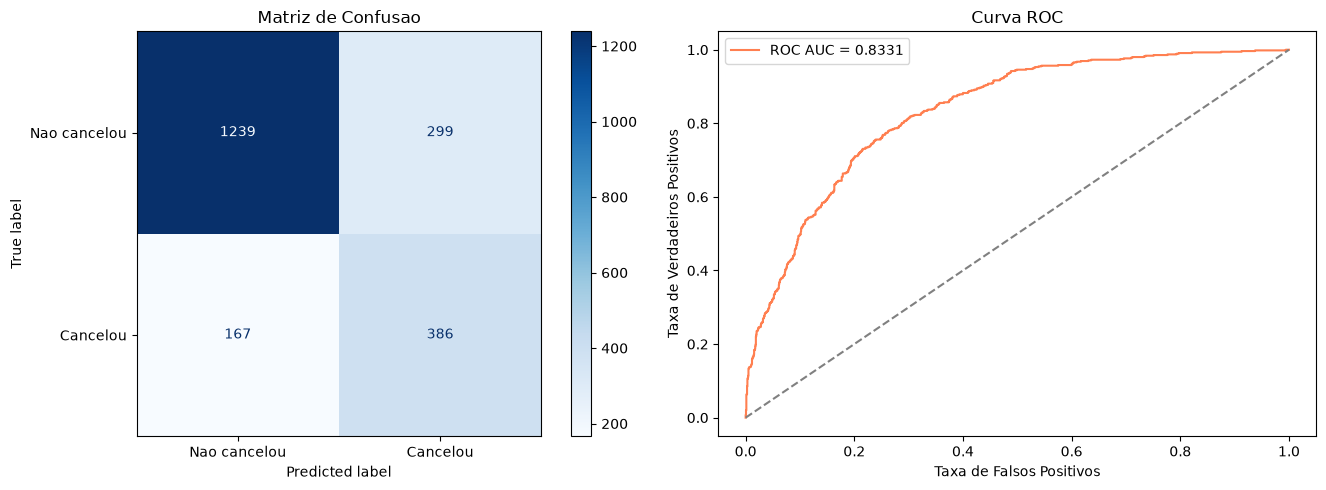

Path                                                          acuracia    f1_score    precisao    recall    roc_auc
notebooks\regressao_logistica\historico\metrics\metrics.json  0.77714     0.62359     0.5635      0.69801   0.8331




In [24]:
modelo_regressao_logistica = treinar_modelo(X_train_balanceado, y_train_balanceado)

coeficientes_lasso = pd.Series(modelo_regressao_logistica.coef_[0], index=X_train_balanceado.columns)
features_zeradas_pelo_lasso = coeficientes_lasso[coeficientes_lasso == 0].index.tolist()
print(f"Features zeradas pelo Lasso ({len(features_zeradas_pelo_lasso)}): {features_zeradas_pelo_lasso}")
print("\nCoeficientes ordenados por magnitude:")
print(coeficientes_lasso.sort_values(key=abs, ascending=False).to_string())

metricas = avaliar_modelo(modelo_regressao_logistica, X_test_preparado, y_test)
y_pred = modelo_regressao_logistica.predict(X_test_preparado)
y_proba = modelo_regressao_logistica.predict_proba(X_test_preparado)[:, 1]
matriz_confusao = confusion_matrix(y_test, y_pred)

print()
for nome, valor in metricas.items():
    print(f"{nome}: {valor:.4f}")
print("Matriz de confusao:")
print(matriz_confusao)

# Gráficos: matriz de confusão e curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matriz de Confusao")
axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {metricas['roc_auc']:.4f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de Falsos Positivos")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
axes[1].set_title("Curva ROC")
axes[1].legend()
plt.tight_layout()
plt.show()

# Grava as métricas para o DVC
PASTA_METRICAS.mkdir(parents=True, exist_ok=True)
with open(PASTA_METRICAS / "metrics.json", "w") as arquivo_metricas:
    json.dump(
        {
            **metricas,
            "features_zeradas_pelo_lasso": features_zeradas_pelo_lasso,
            "matriz_confusao": matriz_confusao.tolist(),
        },
        arquivo_metricas,
        indent=4,
    )

# Exibe as métricas registradas
resultado_dvc = subprocess.run(["dvc", "metrics", "show"], cwd="../../..", capture_output=True, text=True)
print(resultado_dvc.stdout)
print(resultado_dvc.stderr)